# Principal Component Analysis Visualization


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [2]:
# Load and standardize the feature matrix.
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(f"Samples: {X.shape[0]}")
print(f"Original features: {X.shape[1]}")
print(f"Classes: {list(data.target_names)}")

Samples: 569
Original features: 30
Classes: [np.str_('malignant'), np.str_('benign')]


## Explained variance

The explained-variance ratio tells us what fraction of the total standardized variance is captured by each principal component. The cumulative ratio helps select the number of components needed for a target amount of information.

In [3]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)
variance_table = pd.DataFrame(
    {
        "Component": np.arange(1, len(pca_full.explained_variance_ratio_) + 1),
        "Explained variance": pca_full.explained_variance_ratio_,
        "Cumulative variance": np.cumsum(pca_full.explained_variance_ratio_),
    }
).set_index("Component")
variance_table.head(10).round(4)

,Explained variance,Cumulative variance
Component,,
1,0.4427,0.4427
2,0.1897,0.6324
3,0.0939,0.7264
4,0.0660,0.7924
5,0.0550,0.8473
6,0.0402,0.8876
7,0.0225,0.9101
8,0.0159,0.9260
9,0.0139,0.9399


In [4]:
# Select the smallest number of components that preserves at least 90% variance.
components_for_90_percent = int(
    np.argmax(variance_table["Cumulative variance"].to_numpy() >= 0.90) + 1
)
print(f"Components needed for at least 90% variance: {components_for_90_percent}")
print(
    f"Variance explained by the first two components: "
    f"{variance_table['Cumulative variance'].iloc[1]:.4f}"
)

Components needed for at least 90% variance: 7
Variance explained by the first two components: 0.6324


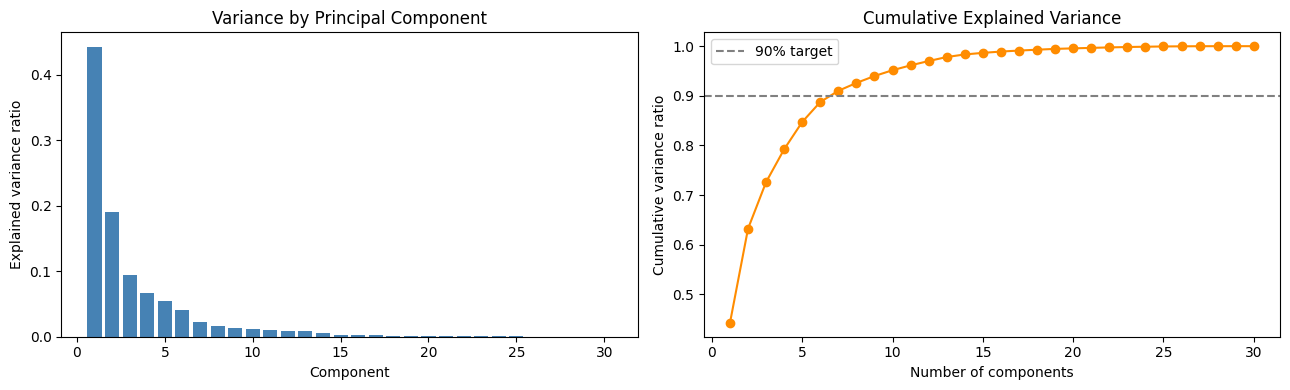

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(
    variance_table.index,
    variance_table["Explained variance"],
    color="steelblue",
)
axes[0].set_title("Variance by Principal Component")
axes[0].set_xlabel("Component")
axes[0].set_ylabel("Explained variance ratio")
axes[1].plot(
    variance_table.index,
    variance_table["Cumulative variance"],
    marker="o",
    color="darkorange",
)
axes[1].axhline(0.90, color="gray", linestyle="--", label="90% target")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative variance ratio")
axes[1].legend()
plt.tight_layout()
plt.show()

## Component loadings and dimensionality reduction

A loading indicates how strongly an original feature contributes to a principal component. The reduced representation can be reconstructed to quantify information lost by using only two components.

In [6]:
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)
loadings = pd.DataFrame(
    pca_2d.components_.T,
    index=X.columns,
    columns=["PC1 loading", "PC2 loading"],
)
print("Features with the largest absolute loadings:")
for component in loadings.columns:
    print(f"\n{component}")
    print(loadings[component].abs().sort_values(ascending=False).head(5).to_string())
X_reconstructed = pca_2d.inverse_transform(X_pca_2d)
reconstruction_mse = np.mean((X_scaled - X_reconstructed) ** 2)
print(f"\nTwo-component reconstruction MSE: {reconstruction_mse:.4f}")

Features with the largest absolute loadings:

PC1 loading
mean concave points     0.260854
mean concavity          0.258400
worst concave points    0.250886
mean compactness        0.239285
worst perimeter         0.236640

PC2 loading
mean fractal dimension     0.366575
fractal dimension error    0.280092
worst fractal dimension    0.275339
mean radius                0.233857
compactness error          0.232716

Two-component reconstruction MSE: 0.3676


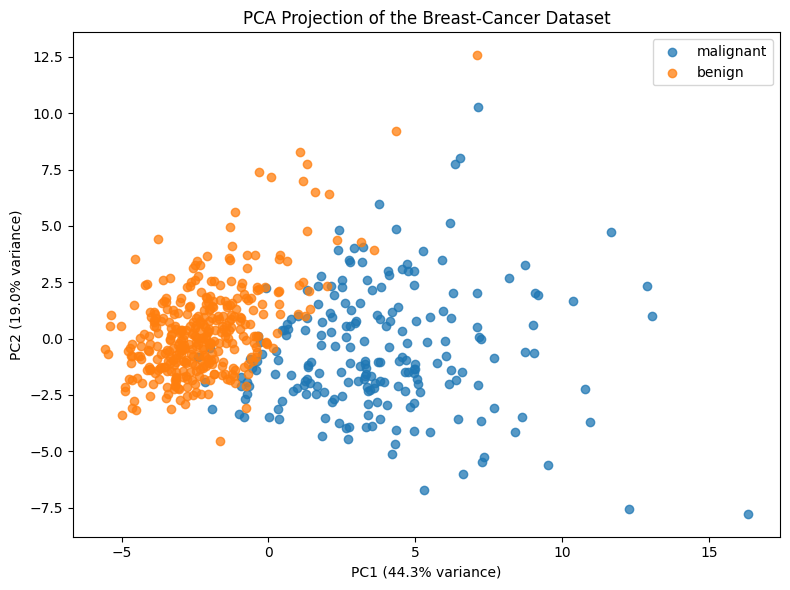

In [7]:
# Visualize the two-dimensional PCA projection.
plt.figure(figsize=(8, 6))
for class_value, class_name in enumerate(data.target_names):
    mask = y == class_value
    plt.scatter(
        X_pca_2d[mask, 0],
        X_pca_2d[mask, 1],
        label=class_name,
        alpha=0.75,
    )
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} variance)")
plt.title("PCA Projection of the Breast-Cancer Dataset")
plt.legend()
plt.tight_layout()
plt.show()